# Uniform and Exponential Random Numbers (ABA Unit 2, Practical 4)

**Aim:** generate random numbers from uniform and exponential distributions, compare them with theory, and use exponential gaps to simulate customer arrivals.

Run the cells in order (Runtime → Run all). Nothing to install. The note `continuous-distributions-practical` on Sutra explains every step.

In [1]:
# Step 1. Uniform: 10,000 delivery times between 20 and 40 minutes
import numpy as np
import pandas as pd
from scipy import stats

rng = np.random.default_rng(2026)
u = rng.uniform(20, 40, size=10_000)
print(f"Mean {u.mean():.2f} (theory {(20 + 40) / 2})   SD {u.std(ddof=1):.2f} (theory {20 / np.sqrt(12):.2f})")
print(f"P(25 <= X <= 30): simulated {((u >= 25) & (u <= 30)).mean():.4f}, theory {5 / 20:.4f}")

Mean 30.11 (theory 30.0)   SD 5.76 (theory 5.77)
P(25 <= X <= 30): simulated 0.2488, theory 0.2500


In [2]:
# Step 2. Exponential: 10,000 gaps between customers, mean 2 minutes (30 customers an hour)
g = rng.exponential(scale=2, size=10_000)        # scale = mean = 1 / rate
print(f"Mean {g.mean():.3f} (theory 2)   SD {g.std(ddof=1):.3f} (theory 2)")
print(f"P(gap > 3 min) : simulated {(g > 3).mean():.4f}, theory {np.exp(-0.5 * 3):.4f}")
print(f"P(gap <= 1 min): simulated {(g <= 1).mean():.4f}, theory {1 - np.exp(-0.5 * 1):.4f}")

Mean 1.975 (theory 2)   SD 1.991 (theory 2)
P(gap > 3 min) : simulated 0.2196, theory 0.2231
P(gap <= 1 min): simulated 0.3967, theory 0.3935


In [3]:
# Step 3. Memoryless: having waited 3 minutes, is a further 2-minute wait just as likely?
print(f"P(gap > 5 | gap > 3) = {(g[g > 3] > 5).mean():.4f}")
print(f"P(gap > 2)           = {(g > 2).mean():.4f}   theory for both: {np.exp(-0.5 * 2):.4f}")

P(gap > 5 | gap > 3) = 0.3643
P(gap > 2)           = 0.3610   theory for both: 0.3679


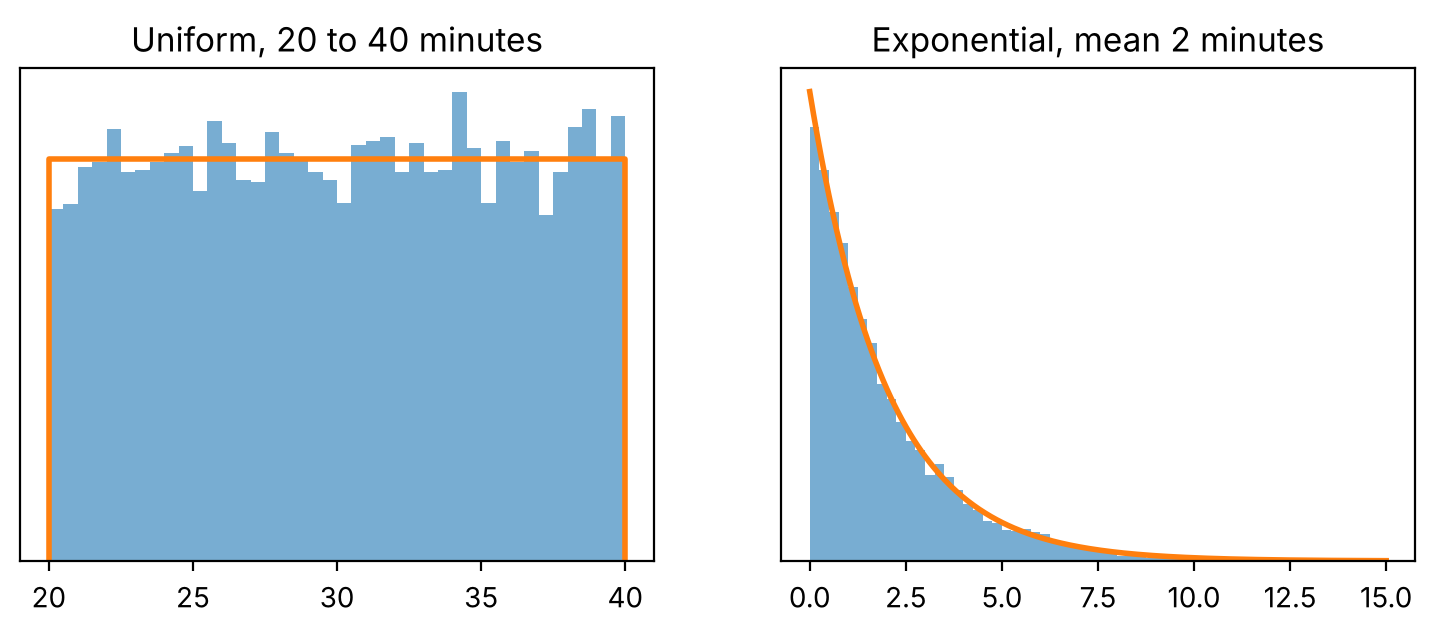

In [4]:
# Step 4. Histograms with the theoretical density curves
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(9, 3.2))
axes[0].hist(u, bins=40, density=True, color="tab:blue", alpha=0.6)
axes[0].plot([20, 20, 40, 40], [0, 1 / 20, 1 / 20, 0], color="tab:orange", lw=2)
axes[0].set_title("Uniform, 20 to 40 minutes")
axes[1].hist(g, bins=60, range=(0, 15), density=True, color="tab:blue", alpha=0.6)
x = np.linspace(0, 15, 300)
axes[1].plot(x, stats.expon.pdf(x, scale=2), color="tab:orange", lw=2)
axes[1].set_title("Exponential, mean 2 minutes")
for ax in axes:
    ax.set_yticks([])
plt.show()

In [5]:
# Step 5. Simulate 10,000 hours of arrivals by adding up exponential gaps
gaps = rng.exponential(scale=2, size=(10_000, 80))   # 80 gaps per hour is always enough here
arrival_times = gaps.cumsum(axis=1)
counts = (arrival_times <= 60).sum(axis=1)           # customers arriving within 60 minutes
print(f"Customers per hour: mean {counts.mean():.2f}, variance {counts.var(ddof=1):.2f} (Poisson: both 30)")
table = pd.DataFrame({"simulated": pd.Series(counts).value_counts(normalize=True).sort_index(),
                      "Poisson(30)": stats.poisson.pmf(np.arange(counts.max() + 1), 30)[pd.Series(counts).value_counts().sort_index().index]})
print(table.loc[[20, 25, 30, 35, 40]].round(4).to_string())

Customers per hour: mean 30.12, variance 29.61 (Poisson: both 30)
    simulated  Poisson(30)
20     0.0124       0.0134
25     0.0516       0.0511
30     0.0732       0.0726
35     0.0473       0.0453
40     0.0132       0.0139


In [6]:
# Step 6. Every distribution can be built from uniform numbers (inverse transform)
r = rng.random(10_000)                 # uniform on 0 to 1
expo = -2 * np.log(1 - r)              # turns uniform numbers into exponential gaps, mean 2
print(f"From uniform numbers: mean {expo.mean():.3f}, SD {expo.std(ddof=1):.3f} (exponential theory: 2 and 2)")

From uniform numbers: mean 1.971, SD 2.001 (exponential theory: 2 and 2)
